# Employee Attrition Prediction & Retention Intelligence

**Advanced ML Final Project** | Binary classification: will an employee leave the company?

**Dataset:** Kaggle `stealthtechnologies/employee-attrition-dataset` (synthetic). `train.csv` = 59,598 rows, `test.csv` = 14,900 rows, 24 columns.

**Pipeline in this notebook**

1. Load data and exploratory data analysis (EDA)
2. Baseline models and preprocessing pipeline
3. Comparison of 4 models (hold-out split, then stratified 5-fold CV)
4. Hyperparameter tuning of the best model (`RandomizedSearchCV`)
5. Final evaluation on the separate `test.csv`
6. Explainability (feature importance and SHAP)
7. Saving the model for the Streamlit app

> The data-quality checks (logical inconsistencies, intentionally **not** cleaned) are in the companion notebook `Data_Quality_Assessment.ipynb`.

## 1. Load data

In [ ]:
from pathlib import Path

import pandas as pd
import numpy as np


def find_file(name):
    # Works from the repo root (./data), next to the notebook, or in Colab (/content)
    for folder in ["data", ".", "..", "/content"]:
        path = Path(folder) / name
        if path.exists():
            return path
    raise FileNotFoundError(f"{name} not found. Put it in ./data/ or next to this notebook.")


# Load datasets
train = pd.read_csv(find_file("train.csv"))
test = pd.read_csv(find_file("test.csv"))

# Check dataset dimensions
print("Training Set Shape:", train.shape)
print("Testing Set Shape:", test.shape)

# Display first 5 rows
display(train.head())

Training Set Shape: (59598, 24)
Testing Set Shape: (14900, 24)


,Employee ID,Age,Gender,Years at Company,Job Role,Monthly Income,Work-Life Balance,Job Satisfaction,Performance Rating,Number of Promotions,...,Number of Dependents,Job Level,Company Size,Company Tenure,Remote Work,Leadership Opportunities,Innovation Opportunities,Company Reputation,Employee Recognition,Attrition
0,8410,31,Male,19,Education,5390,Excellent,Medium,Average,2,...,0,Mid,Medium,89,No,No,No,Excellent,Medium,Stayed
1,64756,59,Female,4,Media,5534,Poor,High,Low,3,...,3,Mid,Medium,21,No,No,No,Fair,Low,Stayed
2,30257,24,Female,10,Healthcare,8159,Good,High,Low,0,...,3,Mid,Medium,74,No,No,No,Poor,Low,Stayed
3,65791,36,Female,7,Education,3989,Good,High,High,1,...,2,Mid,Small,50,Yes,No,No,Good,Medium,Stayed
4,65026,56,Male,41,Education,4821,Fair,Very High,Average,0,...,0,Senior,Medium,68,No,No,No,Fair,Medium,Stayed


## 2. EDA: dataset overview
Dimensions, data types, missing values, duplicates, target distribution (47.5% Left vs 52.5% Stayed, so the classes are roughly balanced).

In [ ]:
import pandas as pd
import numpy as np

print("=" * 50)
print("1. DATASET DIMENSIONS")
print("=" * 50)

print("Train:", train.shape)
print("Test:", test.shape)

print("\n2. DATA TYPES")
print(train.dtypes.value_counts())

print("\n3. MISSING VALUES")
display(train.isnull().sum().sort_values(ascending=False))

print("\n4. DUPLICATES")
print("Duplicate rows:", train.duplicated().sum())
print("Duplicate Employee IDs:", train["Employee ID"].duplicated().sum())

print("\n5. TARGET DISTRIBUTION")
display(train["Attrition"].value_counts())
display(train["Attrition"].value_counts(normalize=True) * 100)

print("\n6. NUMERICAL FEATURES")
display(train.select_dtypes(include=np.number).columns.tolist())

print("\n7. CATEGORICAL FEATURES")
display(train.select_dtypes(include="object").columns.tolist())

1. DATASET DIMENSIONS
Train: (59598, 24)
Test: (14900, 24)

2. DATA TYPES
object    16
int64      8
Name: count, dtype: int64

3. MISSING VALUES


,0
Employee ID,0
Age,0
Gender,0
Years at Company,0
Job Role,0
Monthly Income,0
Work-Life Balance,0
Job Satisfaction,0
Performance Rating,0
Number of Promotions,0



4. DUPLICATES
Duplicate rows: 0
Duplicate Employee IDs: 0

5. TARGET DISTRIBUTION


,count
Attrition,
Stayed,31260
Left,28338


,proportion
Attrition,
Stayed,52.451425
Left,47.548575



6. NUMERICAL FEATURES


['Employee ID',
 'Age',
 'Years at Company',
 'Monthly Income',
 'Number of Promotions',
 'Distance from Home',
 'Number of Dependents',
 'Company Tenure']


7. CATEGORICAL FEATURES


['Gender',
 'Job Role',
 'Work-Life Balance',
 'Job Satisfaction',
 'Performance Rating',
 'Overtime',
 'Education Level',
 'Marital Status',
 'Job Level',
 'Company Size',
 'Remote Work',
 'Leadership Opportunities',
 'Innovation Opportunities',
 'Company Reputation',
 'Employee Recognition',
 'Attrition']

### Further checks
Duplicates ignoring `Employee ID`, train/test ID overlap, numeric statistics, category counts, and IQR outlier counts.

In [ ]:
# 1. Check duplicate records ignoring Employee ID
print("Duplicates ignoring Employee ID:",
      train.drop(columns=["Employee ID"]).duplicated().sum())

# 2. Check train-test Employee ID overlap
overlap = set(train["Employee ID"]) & set(test["Employee ID"])
print("Train-Test ID overlap:", len(overlap))

# 3. Numerical statistics
print("\nNUMERICAL STATISTICS")
display(train.describe().T)

# 4. Categorical values
print("\nCATEGORICAL UNIQUE VALUES")
cat_cols = train.select_dtypes(include="object").columns.drop("Attrition")

for col in cat_cols:
    print(f"\n{col}:")
    print(train[col].value_counts())

# 5. Outlier detection using IQR
print("\nOUTLIER CHECK")
num_cols = train.select_dtypes(include=np.number).columns.drop("Employee ID")

for col in num_cols:
    q1 = train[col].quantile(0.25)
    q3 = train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((train[col] < lower) | (train[col] > upper)).sum()

    print(f"{col}: {count} potential outliers")

Duplicates ignoring Employee ID: 0
Train-Test ID overlap: 0

NUMERICAL STATISTICS


,count,mean,std,min,25%,50%,75%,max
Employee ID,59598.0,37227.118729,21519.150028,1.0,18580.25,37209.5,55876.75,74498.0
Age,59598.0,38.565875,12.079673,18.0,28.00,39.0,49.00,59.0
Years at Company,59598.0,15.753901,11.245981,1.0,7.00,13.0,23.00,51.0
Monthly Income,59598.0,7302.397983,2151.457423,1316.0,5658.00,7354.0,8880.00,16149.0
Number of Promotions,59598.0,0.832578,0.994991,0.0,0.00,1.0,2.00,4.0
Distance from Home,59598.0,50.007651,28.466459,1.0,25.00,50.0,75.00,99.0
Number of Dependents,59598.0,1.648075,1.555689,0.0,0.00,1.0,3.00,6.0
Company Tenure,59598.0,55.758415,25.411090,2.0,36.00,56.0,76.00,128.0



CATEGORICAL UNIQUE VALUES

Gender:
Gender
Male      32739
Female    26859
Name: count, dtype: int64

Job Role:
Job Role
Technology    15507
Healthcare    13642
Education     12490
Media          9574
Finance        8385
Name: count, dtype: int64

Work-Life Balance:
Work-Life Balance
Good         22528
Fair         18046
Excellent    10719
Poor          8305
Name: count, dtype: int64

Job Satisfaction:
Job Satisfaction
High         29779
Very High    12111
Medium       11817
Low           5891
Name: count, dtype: int64

Performance Rating:
Performance Rating
Average          35810
High             11888
Below Average     8950
Low               2950
Name: count, dtype: int64

Overtime:
Overtime
No     40148
Yes    19450
Name: count, dtype: int64

Education Level:
Education Level
Bachelor’s Degree    17826
Associate Degree     14915
Master’s Degree      12020
High School          11748
PhD                   3089
Name: count, dtype: int64

Marital Status:
Marital Status
Married     29908


## 3. EDA: features vs attrition
Average numeric values and attrition rates for each category. Patterns here describe this (synthetic) dataset, not causal facts about real employees.

In [ ]:
# 1. Attrition rate across numerical features
print("NUMERICAL FEATURES BY ATTRITION")

display(
    train.groupby("Attrition")[
        ["Age", "Years at Company", "Monthly Income",
         "Number of Promotions", "Distance from Home",
         "Number of Dependents", "Company Tenure"]
    ].mean().T
)

# 2. Attrition rate across categorical features
print("\nCATEGORICAL FEATURES VS ATTRITION")

categorical_cols = [
    "Gender", "Job Role", "Work-Life Balance",
    "Job Satisfaction", "Performance Rating",
    "Overtime", "Education Level", "Marital Status",
    "Job Level", "Company Size", "Remote Work",
    "Leadership Opportunities", "Innovation Opportunities",
    "Company Reputation", "Employee Recognition"
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    rate = pd.crosstab(
        train[col],
        train["Attrition"],
        normalize="index"
    ) * 100

    display(rate.round(2))

# 3. Check relationship between Years at Company and Company Tenure
print("\nTENURE RELATIONSHIP")

display(
    train[["Years at Company", "Company Tenure"]].describe().T
)

print(
    "Correlation:",
    train["Years at Company"].corr(train["Company Tenure"])
)

NUMERICAL FEATURES BY ATTRITION


Attrition,Left,Stayed
Age,37.945480,39.128279
Years at Company,14.987226,16.448912
Monthly Income,7276.689533,7325.703359
Number of Promotions,0.748359,0.908925
Distance from Home,52.864987,47.417402
Number of Dependents,1.520079,1.764107
Company Tenure,54.950138,56.491139



CATEGORICAL FEATURES VS ATTRITION

--- Gender ---


Attrition,Left,Stayed
Gender,,
Female,53.16,46.84
Male,42.94,57.06



--- Job Role ---


Attrition,Left,Stayed
Job Role,,
Education,48.72,51.28
Finance,46.80,53.20
Healthcare,47.31,52.69
Media,47.44,52.56
Technology,47.29,52.71


... (25 outputs left out)

Attrition,Left,Stayed
Employee Recognition,,
High,47.18,52.82
Low,47.83,52.17
Medium,47.71,52.29
Very High,46.14,53.86



TENURE RELATIONSHIP


,count,mean,std,min,25%,50%,75%,max
Years at Company,59598.0,15.753901,11.245981,1.0,7.0,13.0,23.0,51.0
Company Tenure,59598.0,55.758415,25.411090,2.0,36.0,56.0,76.0,128.0


Correlation: 0.44218001443585614


## 4. Preprocessing and baseline models
Median imputation + scaling for numeric columns, most-frequent imputation + one-hot encoding for categorical columns. A `DummyClassifier` and Logistic Regression give the baseline to beat (80/20 stratified validation split).

In [ ]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)

# 1. Separate features and target
X = train.drop(columns=["Attrition", "Employee ID"]).copy()
y = train["Attrition"].map({"Stayed": 0, "Left": 1})

# 2. Force correct data types
for col in X.columns:
    if pd.api.types.is_numeric_dtype(X[col]):
        X[col] = pd.to_numeric(X[col], errors="coerce").astype("float64")
    else:
        X[col] = X[col].astype("object")

# Convert target to regular NumPy integers
y = y.astype("int64")

# 3. Identify columns
num_cols = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()

print("Numeric columns:", len(num_cols))
print("Categorical columns:", len(cat_cols))
print("\nRemaining StringDtype columns:",
      X.select_dtypes(include=["string"]).columns.tolist())

# 4. Preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("cat", categorical_pipeline, cat_cols)
])

# 5. Train-validation split
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 6. Models
models = {
    "Dummy Classifier": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ])
}

# 7. Train and evaluate
for name, model in models.items():

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    print("Accuracy:", round(accuracy_score(y_val, predictions), 4))
    print("Precision:", round(precision_score(y_val, predictions, zero_division=0), 4))
    print("Recall:", round(recall_score(y_val, predictions, zero_division=0), 4))
    print("F1 Score:", round(f1_score(y_val, predictions, zero_division=0), 4))

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_val)[:, 1]
        print("ROC-AUC:", round(roc_auc_score(y_val, probabilities), 4))

    print("\nClassification Report:")
    print(classification_report(
        y_val, predictions,
        target_names=["Stayed", "Left"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_val, predictions))


## 5. Model comparison (hold-out validation)
Logistic Regression, Random Forest, Extra Trees, and Gradient Boosting on the same validation split.

In [ ]:
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

models_to_compare = {
    "Logistic Regression": models["Logistic Regression"],

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1,
            min_samples_leaf=2
        ))
    ]),

    "Extra Trees": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", ExtraTreesClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1,
            min_samples_leaf=2
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ))
    ])
}

results = []

for name, model in models_to_compare.items():
    print("Training:", name)

    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    prob = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1 Score": f1_score(y_val, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, prob)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4).sort_values("F1 Score", ascending=False))

Training: Logistic Regression
Training: Random Forest
Training: Extra Trees
Training: Gradient Boosting


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Gradient Boosting,0.7540,0.7444,0.7352,0.7397,0.8484
Logistic Regression,0.7479,0.7375,0.7295,0.7335,0.8422
Random Forest,0.7458,0.7353,0.7272,0.7312,0.8370
Extra Trees,0.7352,0.7232,0.7179,0.7206,0.8248


## 6. Stratified 5-fold cross-validation
A more reliable comparison than a single split. Gradient Boosting is best on F1 and ROC-AUC, so it is the model we tune.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models_to_compare.items():

    print("Evaluating:", name)

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "F1 Mean": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std(),
        "ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std()
    })

cv_df = pd.DataFrame(cv_results)

display(
    cv_df.sort_values("F1 Mean", ascending=False).round(4)
)

Evaluating: Logistic Regression
Evaluating: Random Forest
Evaluating: Extra Trees
Evaluating: Gradient Boosting


,Model,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std
3,Gradient Boosting,0.7569,0.0035,0.7431,0.0041,0.8484,0.0039
0,Logistic Regression,0.7503,0.0063,0.7366,0.0073,0.8411,0.0040
1,Random Forest,0.7472,0.0046,0.7325,0.0054,0.8367,0.0032
2,Extra Trees,0.7403,0.0048,0.7253,0.0055,0.8270,0.0033


## 7. Hyperparameter tuning (Gradient Boosting)
`RandomizedSearchCV` (8 candidates, 3-fold CV, scored on F1). The best model is refit on the full training set.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

gb_pipeline = models_to_compare["Gradient Boosting"]

param_grid = {
    "classifier__n_estimators": [100, 150, 200, 250],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__max_depth": [2, 3, 4],
    "classifier__min_samples_leaf": [2, 5, 10],
    "classifier__subsample": [0.8, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=param_grid,
    n_iter=8,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=1
)

random_search.fit(X, y)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1:")
print(round(random_search.best_score_, 4))

best_model = random_search.best_estimator_

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters:
{'classifier__subsample': 0.8, 'classifier__n_estimators': 250, 'classifier__min_samples_leaf': 5, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.1}

Best Cross-Validation F1:
0.7462


## 8. Final evaluation on the separate test set
First a quick check that `test.csv` has the same columns and a labelled target, then the final metrics. `test.csv` was **not** used for model selection or tuning.

In [ ]:
print(test.columns.tolist())
print(test["Attrition"].value_counts(dropna=False))

['Employee ID', 'Age', 'Gender', 'Years at Company', 'Job Role', 'Monthly Income', 'Work-Life Balance', 'Job Satisfaction', 'Performance Rating', 'Number of Promotions', 'Overtime', 'Distance from Home', 'Education Level', 'Marital Status', 'Number of Dependents', 'Job Level', 'Company Size', 'Company Tenure', 'Remote Work', 'Leadership Opportunities', 'Innovation Opportunities', 'Company Reputation', 'Employee Recognition', 'Attrition']
Attrition
Stayed    7868
Left      7032
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

X_test = test.drop(columns=["Attrition", "Employee ID"])
y_test = test["Attrition"].map({"Stayed": 0, "Left": 1})

# best_model was already refitted on the complete training set
test_predictions = best_model.predict(X_test)
test_probabilities = best_model.predict_proba(X_test)[:, 1]

print("FINAL TEST RESULTS")
print("=" * 40)

print("Accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Precision:", round(precision_score(y_test, test_predictions), 4))
print("Recall:", round(recall_score(y_test, test_predictions), 4))
print("F1 Score:", round(f1_score(y_test, test_predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Stayed", "Left"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

FINAL TEST RESULTS
Accuracy: 0.7612
Precision: 0.7484
Recall: 0.7442
F1 Score: 0.7463
ROC-AUC: 0.8531

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.77      0.78      0.77      7868
        Left       0.75      0.74      0.75      7032

    accuracy                           0.76     14900
   macro avg       0.76      0.76      0.76     14900
weighted avg       0.76      0.76      0.76     14900

Confusion Matrix:
[[6109 1759]
 [1799 5233]]


## 9. Explainability
### Built-in feature importance (Gradient Boosting)

,Feature,Importance
35,cat__Marital Status_Single,0.200543
38,cat__Job Level_Senior,0.135655
36,cat__Job Level_Entry,0.118475
42,cat__Remote Work_No,0.091166
15,cat__Work-Life Balance_Fair,0.044050
3,num__Number of Promotions,0.043943
43,cat__Remote Work_Yes,0.043915
17,cat__Work-Life Balance_Poor,0.041779
4,num__Distance from Home,0.034268
5,num__Number of Dependents,0.032520


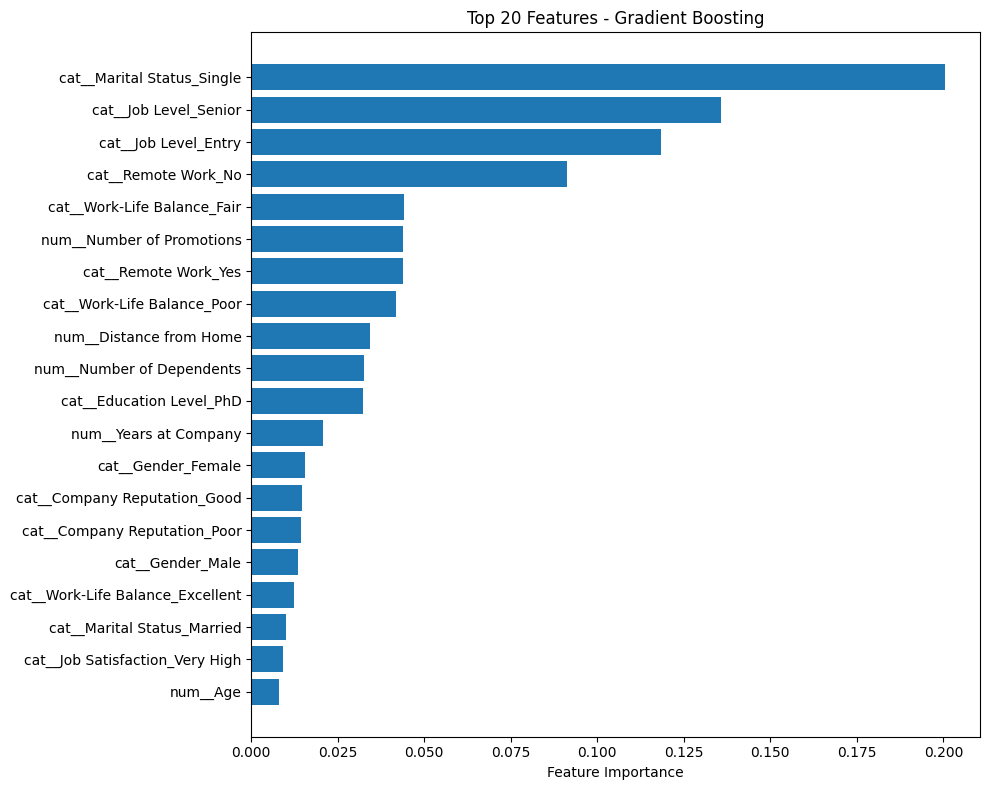

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract the fitted preprocessing and classifier steps
preprocessor_fitted = best_model.named_steps["preprocessor"]
classifier = best_model.named_steps["classifier"]

# Get feature names after encoding
feature_names = preprocessor_fitted.get_feature_names_out()

# Get feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": classifier.feature_importances_
})

# Sort and display top 20
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

top_features = importance_df.head(20)

display(top_features)

# Plot
plt.figure(figsize=(10, 8))
plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)
plt.xlabel("Feature Importance")
plt.title("Top 20 Features - Gradient Boosting")
plt.tight_layout()
plt.show()

### SHAP analysis
SHAP is only needed for this notebook, not for the Streamlit app. A sample of 500 test rows is explained to keep it fast.

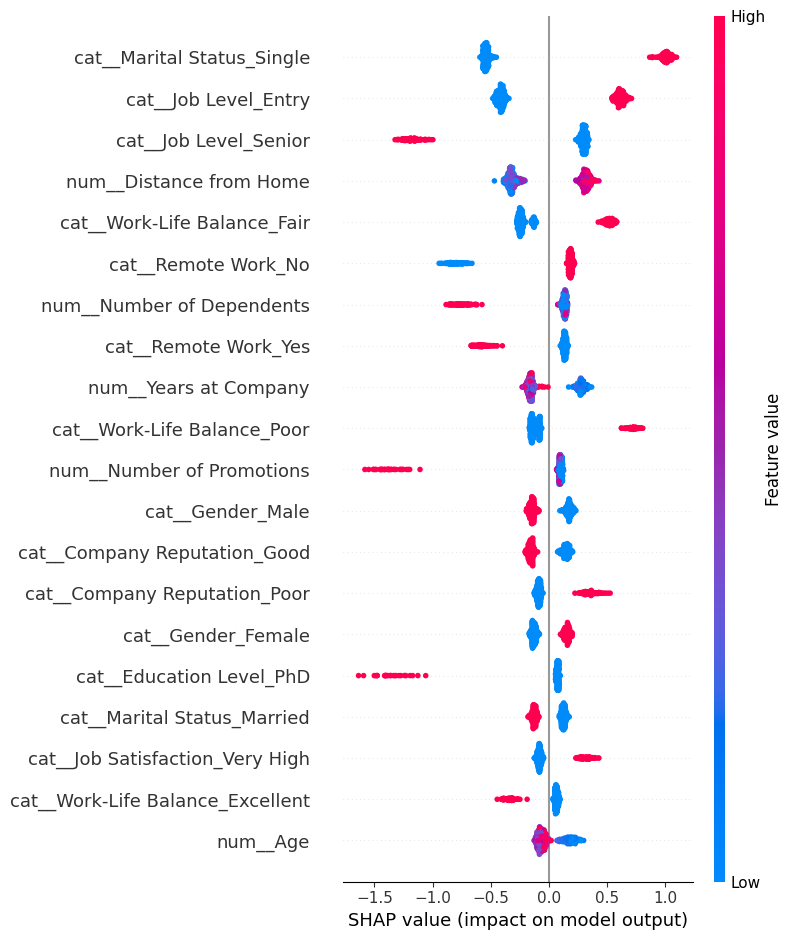

In [ ]:
%pip install -q shap

import shap
import matplotlib.pyplot as plt
import numpy as np

# Use the fitted Gradient Boosting model
preprocessor_fitted = best_model.named_steps["preprocessor"]
classifier = best_model.named_steps["classifier"]

# Take a sample for explainability
X_shap = X_test.sample(
    n=500,
    random_state=42
)

# Apply the same preprocessing
X_shap_transformed = preprocessor_fitted.transform(X_shap)

if hasattr(X_shap_transformed, "toarray"):
    X_shap_transformed = X_shap_transformed.toarray()

# Get feature names
feature_names = preprocessor_fitted.get_feature_names_out()

# SHAP Tree Explainer
explainer = shap.TreeExplainer(classifier)

shap_values = explainer.shap_values(
    X_shap_transformed
)

# Summary plot
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names,
    max_display=20
)

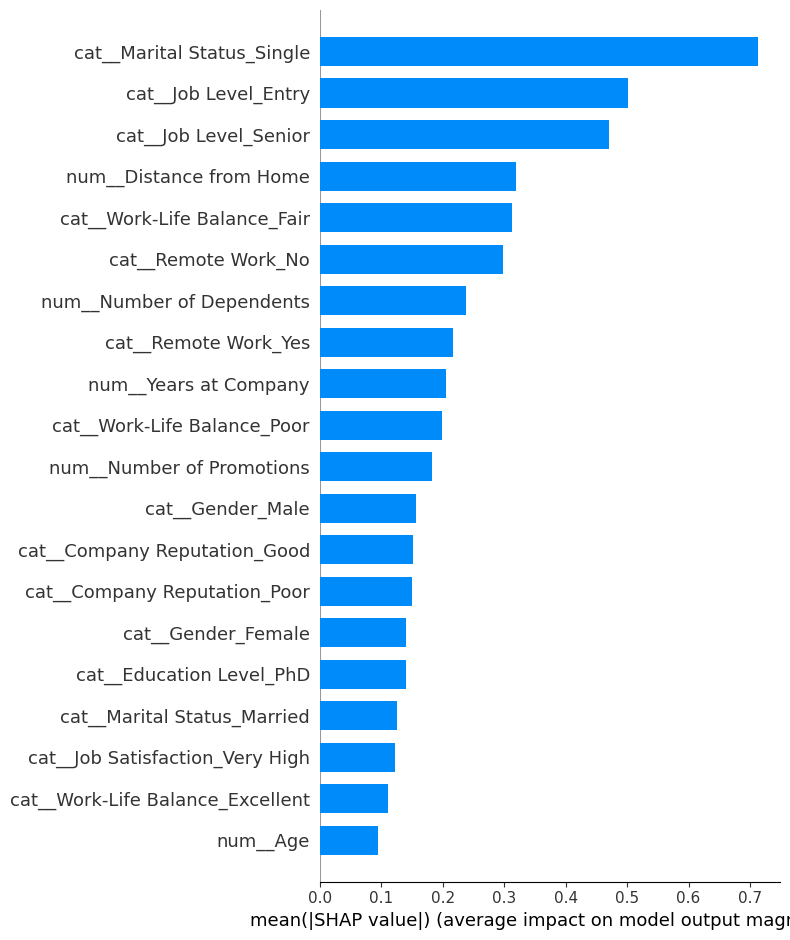

In [ ]:
# Global SHAP Feature Importance

shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20
)

In [ ]:
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_SHAP_Importance": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_SHAP_Importance",
    ascending=False
)

display(shap_importance.head(20).round(5))

,Feature,Mean_SHAP_Importance
35,cat__Marital Status_Single,0.71321
36,cat__Job Level_Entry,0.50103
38,cat__Job Level_Senior,0.47138
4,num__Distance from Home,0.31856
15,cat__Work-Life Balance_Fair,0.31267
42,cat__Remote Work_No,0.29815
5,num__Number of Dependents,0.23780
43,cat__Remote Work_Yes,0.21737
1,num__Years at Company,0.20507
17,cat__Work-Life Balance_Poor,0.19850


## 10. Save the model for the Streamlit app
The complete pipeline (preprocessing + classifier) and the list of input features are saved to `models/`.

In [ ]:
import joblib
import json
import os

os.makedirs("models", exist_ok=True)

# Save the complete pipeline
joblib.dump(
    best_model,
    "models/gradient_boosting_model.pkl"
)

# Save feature names
with open("models/feature_names.json", "w") as f:
    json.dump(
        X.columns.tolist(),
        f,
        indent=4
    )

print("Model saved successfully!")
print("Features saved successfully!")

Model saved successfully!
Features saved successfully!


In [ ]:
import os

print(os.listdir("models"))

['feature_names.json', 'gradient_boosting_model.pkl']


In [ ]:
import shutil

shutil.make_archive("attrition_model", "zip", "models")

# The browser download only exists in Google Colab; locally the files are already in ./models
try:
    from google.colab import files
    files.download("attrition_model.zip")
except ImportError:
    print("Not running in Colab: model files are already saved in ./models")

### Library version used for training
The app's `requirements.txt` pins the same scikit-learn version, so the saved model loads correctly when deployed.

In [ ]:
import sklearn
print(sklearn.__version__)

1.6.1


## 11. Summary

| Step | Result |
|------|--------|
| Best model (5-fold CV) | Gradient Boosting: accuracy 0.7569, F1 0.7431, ROC-AUC 0.8484 |
| Tuned parameters | 250 trees, learning rate 0.1, max depth 3, min samples leaf 5, subsample 0.8 (CV F1 0.7462) |
| **Final test results** | Accuracy **76.12%**, Precision 74.84%, Recall 74.42%, F1 **74.63%**, ROC-AUC **85.31%** |
| Confusion matrix (test) | `[[6109, 1759], [1799, 5233]]` |

**Main drivers (feature importance and SHAP agree):** marital status (single), job level (entry / senior), remote work, work-life balance, distance from home, and number of promotions.

**Limitations**

- The dataset is **synthetic** and contains logical inconsistencies (see `Data_Quality_Assessment.ipynb`), so results describe patterns in this dataset, not real-world causes of attrition.
- Importance and SHAP values show what the model uses, not what *causes* people to leave.
- `Gender` appears among the model's inputs; in a real deployment this should be reviewed for fairness before use in HR decisions.